Mounted at /content/drive
=== BẮT ĐẦU THỰC HIỆN BÀI 4 ===

--- 15. BẢNG THỐNG KÊ MÔ TẢ DỮ LIỆU SỐ ---


,count,mean,median,min,max,std,Q1,Q3,IQR
Price_VND,216.0,1.016606e+06,1018000.0,-120000.0,1993000.0,581917.126486,501000.0,1526250.00,1025250.00
Rating,214.0,3.934579e+00,4.0,-1.0,6.5,0.742297,3.4,4.50,1.10
Purchase_Count,226.0,1.284699e+03,1310.5,-20.0,2494.0,726.308840,659.5,1903.75,1244.25
Stock,228.0,1.963158e+02,146.0,-15.0,9999.0,657.406281,93.0,217.75,124.75
Weight,225.0,1.047369e+03,1042.0,-200.0,1973.0,576.253991,522.0,1561.00,1039.00


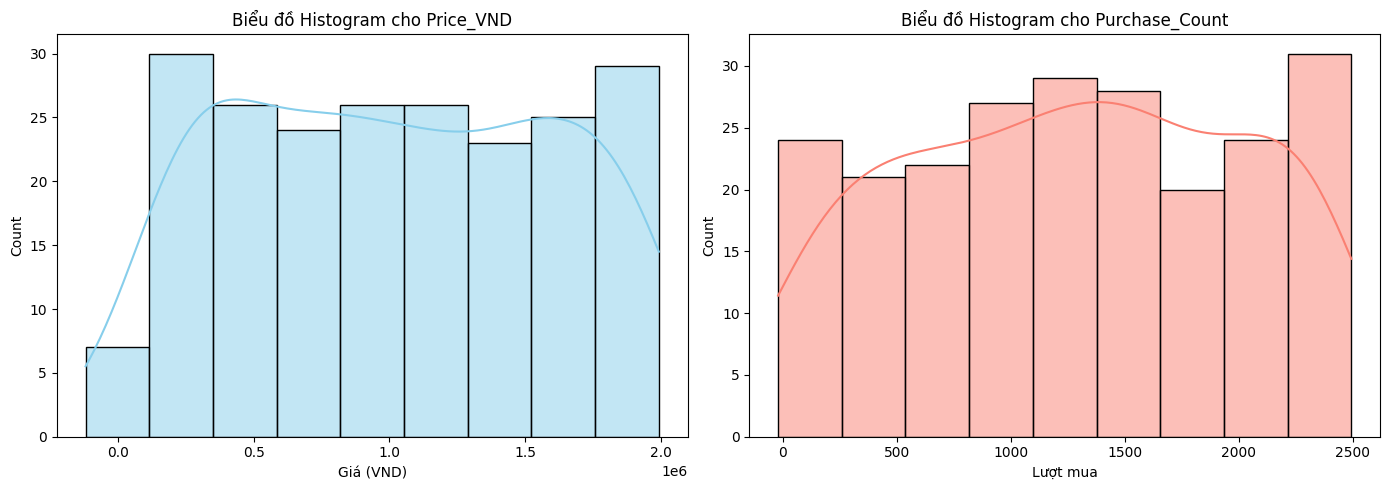

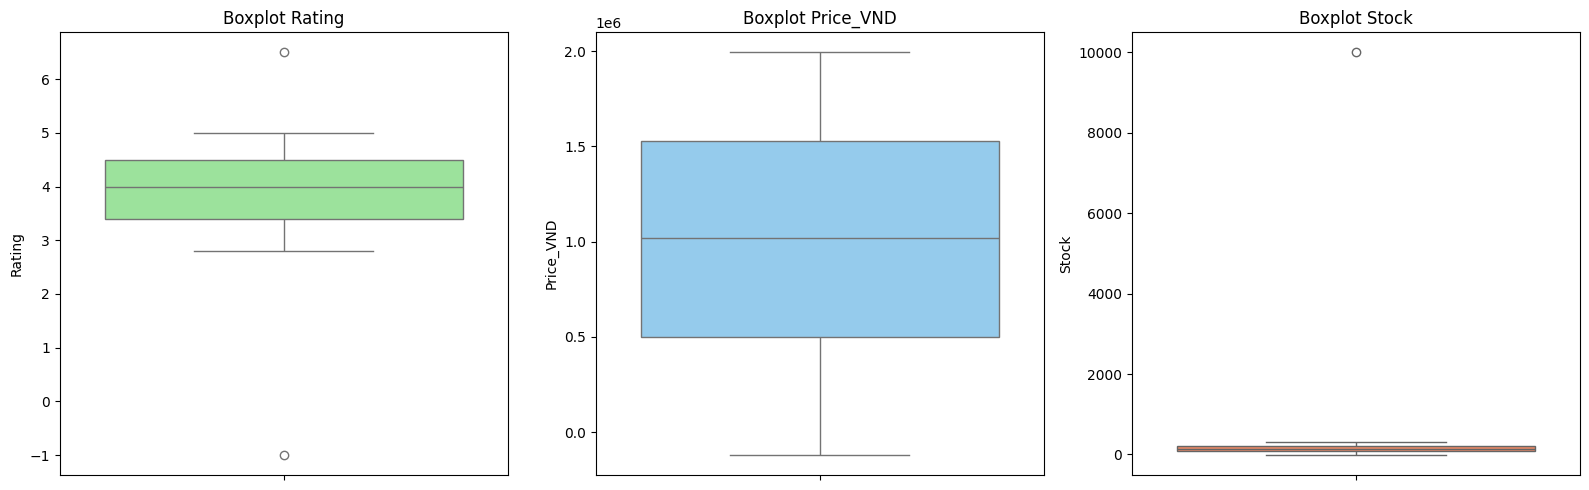

/tmp/ipykernel_456/395363532.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.index.astype(str), y=category_counts.values, palette='viridis')


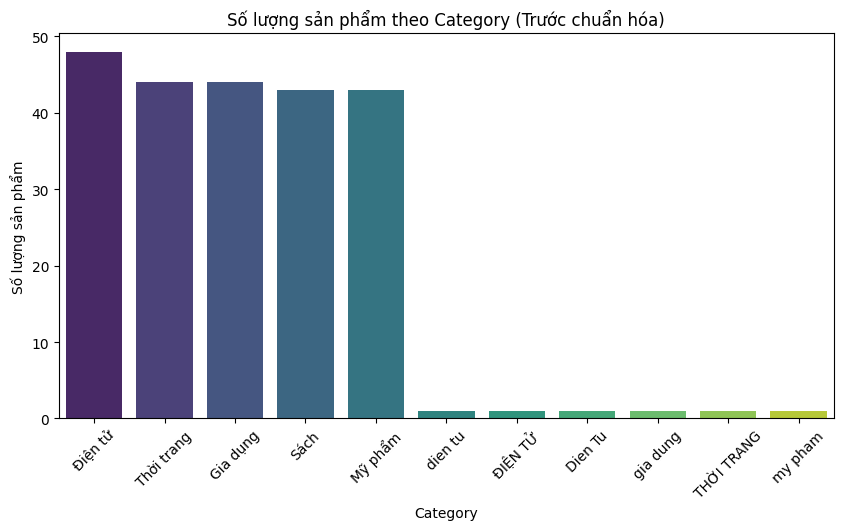


--- 19. NHẬN XÉT CHI TIẾT ---
1. [Ảnh hưởng của dữ liệu lỗi đến biểu đồ]: Biểu đồ cột Category trước chuẩn hóa bị phân tán thành nhiều cột trùng lặp (ví dụ: 'electronics', 'ELECTRONICS', 'electronics ') do lỗi ghi hoa/thường và khoảng trắng thừa, dẫn đến thống kê tần suất bị sai lệch đáng kể.
2. [Giá trị ngoại lệ (Outliers)]: Biểu đồ Boxplot của Price_VND và Rating xuất hiện nhiều điểm ngoại lệ nằm xa khung IQR (Rating có giá trị > 5 hoặc âm, Stock có giá trị âm), phản ánh dữ liệu chưa qua làm sạch chứa nhiều sai sót nhập liệu.
3. [Phân phối dữ liệu]: Biểu đồ Histogram của Purchase_Count và Price_VND bị lệch mạnh (Skewed) do có sự chênh lệch lớn giữa các giá trị cực đoan và phần lớn dữ liệu còn lại.


In [1]:
# ==========================================
# BÀI 4: THỐNG KÊ MÔ TẢ VÀ TRỰC QUAN BAN ĐẦU
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 1. Mount Drive và Đọc dữ liệu
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Nhap_Mon_Hoc_May/Buoi2/Du_lieu_thuc_hanh_chuan_bi_du_lieu.xlsx'

df_raw = pd.read_excel(file_path, sheet_name='Du_lieu_tho')
df = df_raw.copy()

print("=== BẮT ĐẦU THỰC HIỆN BÀI 4 ===\n")

# ------------------------------------------
# Yêu cầu 15: Thống kê mô tả (count, mean, median, min, max, std, Q1, Q3, IQR)
# ------------------------------------------
print("--- 15. BẢNG THỐNG KÊ MÔ TẢ DỮ LIỆU SỐ ---")
num_cols = ['Price_VND', 'Rating', 'Purchase_Count', 'Stock', 'Weight']

# Ép kiểu dữ liệu sang dạng số (lỗi biến thành NaN) để tính toán
df_numeric = df[num_cols].apply(pd.to_numeric, errors='coerce')

# Thống kê cơ bản bằng describe
stats = df_numeric.describe().T[['count', 'mean', '50%', 'min', 'max', 'std']]
stats.rename(columns={'50%': 'median'}, inplace=True)

# Tính Q1, Q3 và IQR
stats['Q1'] = df_numeric.quantile(0.25)
stats['Q3'] = df_numeric.quantile(0.75)
stats['IQR'] = stats['Q3'] - stats['Q1']

# Sắp xếp lại đúng thứ tự yêu cầu
stats = stats[['count', 'mean', 'median', 'min', 'max', 'std', 'Q1', 'Q3', 'IQR']]
display(stats)


# ------------------------------------------
# Yêu cầu 16: Vẽ Histogram cho Price_VND và Purchase_Count
# ------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_numeric['Price_VND'].dropna(), kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Biểu đồ Histogram cho Price_VND')
axes[0].set_xlabel('Giá (VND)')

sns.histplot(df_numeric['Purchase_Count'].dropna(), kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Biểu đồ Histogram cho Purchase_Count')
axes[1].set_xlabel('Lượt mua')

plt.tight_layout()
plt.show()


# ------------------------------------------
# Yêu cầu 17: Vẽ Boxplot cho Rating, Price_VND, Stock
# ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(y=df_numeric['Rating'], ax=axes[0], color='lightgreen')
axes[0].set_title('Boxplot Rating')

sns.boxplot(y=df_numeric['Price_VND'], ax=axes[1], color='lightskyblue')
axes[1].set_title('Boxplot Price_VND')

sns.boxplot(y=df_numeric['Stock'], ax=axes[2], color='coral')
axes[2].set_title('Boxplot Stock')

plt.tight_layout()
plt.show()


# ------------------------------------------
# Yêu cầu 18: Biểu đồ cột số sản phẩm theo Category (trước chuẩn hóa)
# ------------------------------------------
plt.figure(figsize=(10, 5))
category_counts = df['Category'].value_counts(dropna=False)
sns.barplot(x=category_counts.index.astype(str), y=category_counts.values, palette='viridis')

plt.title('Số lượng sản phẩm theo Category (Trước chuẩn hóa)')
plt.xlabel('Category')
plt.ylabel('Số lượng sản phẩm')
plt.xticks(rotation=45)
plt.show()


# ------------------------------------------
# Yêu cầu 19: Nhận xét kết quả
# ------------------------------------------
print("\n--- 19. NHẬN XÉT CHI TIẾT ---")
print("1. [Ảnh hưởng của dữ liệu lỗi đến biểu đồ]: Biểu đồ cột Category trước chuẩn hóa bị phân tán thành nhiều cột trùng lặp (ví dụ: 'electronics', 'ELECTRONICS', 'electronics ') do lỗi ghi hoa/thường và khoảng trắng thừa, dẫn đến thống kê tần suất bị sai lệch đáng kể.")
print("2. [Giá trị ngoại lệ (Outliers)]: Biểu đồ Boxplot của Price_VND và Rating xuất hiện nhiều điểm ngoại lệ nằm xa khung IQR (Rating có giá trị > 5 hoặc âm, Stock có giá trị âm), phản ánh dữ liệu chưa qua làm sạch chứa nhiều sai sót nhập liệu.")
print("3. [Phân phối dữ liệu]: Biểu đồ Histogram của Purchase_Count và Price_VND bị lệch mạnh (Skewed) do có sự chênh lệch lớn giữa các giá trị cực đoan và phần lớn dữ liệu còn lại.")